# Evaluation of the rent models

Scores every model that has saved its predictions under `predictions/`, so models trained elsewhere take part by dropping their files there (the format is described in `evaluation_utils.py`):

| folder | rows | what the predictions are |
|---|---|---|
| `predictions/val/<model>.csv` | the 35,158 validation rows (2024-04..2025-03) | **held-out**: the model fitted on 2021-01..2024-03 |
| `predictions/train/<model>.csv` | the 149,999 train + validation rows | **in-sample**: the final model fitted on 2021-01..2025-03 |
| `predictions/test/<model>.csv` | the 50,000 test rows (2025-03..2026-07), no rents | the final model |
| `predictions/levels/<model>.csv` (optional) | the 67 months | the rent of a fixed set of flats as predicted for each month, for the growth benchmark |

Each file holds `ROW_ID`, the identifier columns of the static features and `prediction`; the actual rents are read from `data/original_dataset/train.csv` by `ROW_ID`.

1. Held-out accuracy (MAE, RMSE, R2, bias in dollars) against month-only references, and by flat type.
2. In-sample accuracy of the final models (the models have seen these rents).
3. Growth forecast for 2026 against the government growth band (the test set has no rents, so the forecast cannot be scored directly).
4. Charts, and the training diagnostics of the neural networks (epoch losses, from their `results/tables/`).

Tables are saved under `tables/`, charts under `charts/`.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import evaluation_utils as eu

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
os.makedirs(eu.TABLE_DIR, exist_ok=True); os.makedirs(eu.CHART_DIR, exist_ok=True)
NN_TABLES = eu.ROOT / '02_modelling' / 'two_stage_models' / 'neural_network' / 'results' / 'tables'      # training statistics of the neural networks
MODEL_STYLE = {'temporal_ffn': ('Temporal network only', eu.HUE['orange']),
               'static_temporal_ffn': ('Static + temporal network (single stage)', eu.HUE['aqua']),
               'two_stage_ffn_rf': ('Two-stage: FFN level x random forest', eu.HUE['violet'])}        # other models: their file name and the next free colour

## 1. Load the predictions and the actual rents

In [2]:
models = eu.list_models()
actual = eu.load_actuals()
preds = {split: {m: eu.load_predictions(m, split) for m in models} for split in ('train', 'val', 'test')}

free = [c for c in eu.HUE_CYCLE if c not in {c for _, c in MODEL_STYLE.values()}]
style = {m: MODEL_STYLE.get(m) or (m, free.pop(0)) for m in models}
label = {m: s[0] for m, s in style.items()}

for split in ('train', 'val'):                                           # attach the actual rent by ROW_ID and check the rows line up
    for m, df in preds[split].items():
        a = actual.loc[df['ROW_ID']]
        assert (a['month'].to_numpy() == df['month'].to_numpy()).all(), (m, split)
        df['actual'], df['FLAT_TYPE'] = a[eu.LABEL].to_numpy(), a['FLAT_TYPE'].to_numpy()
for split in ('train', 'val', 'test'):
    ids = [df['ROW_ID'].to_numpy() for df in preds[split].values()]
    assert all((i == ids[0]).all() for i in ids), f'the models of {split} are not predicting the same rows'
    assert all(df['prediction'].notna().all() for df in preds[split].values())
ref = preds['val'][models[0]]
FIRST_VAL = int(ref['month'].min())
print('models:', models)
print({s: len(next(iter(preds[s].values()))) for s in preds}, f'| validation months {FIRST_VAL}..{int(ref["month"].max())} ({eu.month_label(FIRST_VAL)[0]}..{eu.month_label(ref["month"].max())[0]})')

train_rows = preds['train'][models[0]]
month_mean = train_rows.groupby('month')['actual'].mean()                # actual level of each month 0..50

models: ['static_temporal_ffn', 'temporal_ffn', 'two_stage_ffn_rf']
{'train': 149999, 'val': 35158, 'test': 50000} | validation months 39..50 (2024-04..2025-03)


## 2. Held-out accuracy (validation rows, models fitted on 2021-01..2024-03)

The month-only references use the months before the validation period (and the validation rents themselves for the first): the **monthly mean rent** is the best any model that sees only the month could do (a floor, it is not a forecast),
**carry-forward** repeats the mean rent of the last fitted month, and **straight-line trend** extends a linear fit of the monthly mean rent of the fitted months.

In [3]:
val = preds['val'][models[0]]
fit_months = np.arange(FIRST_VAL)
slope, intercept = np.polyfit(fit_months, month_mean.loc[fit_months], 1)
references = {'monthly mean rent (floor for month-only models)': month_mean.loc[val['month']].to_numpy(),
              f'carry-forward (mean rent of {eu.month_label(FIRST_VAL - 1)[0]})': np.full(len(val), month_mean.loc[FIRST_VAL - 1]),
              'straight-line trend of the monthly mean rent': intercept + slope * val['month'].to_numpy()}
held_out = pd.DataFrame({**{label[m]: eu.regression_metrics(preds['val'][m]['actual'], preds['val'][m]['prediction']) for m in models},
                         **{k: eu.regression_metrics(val['actual'], v) for k, v in references.items()}}).T
held_out.to_csv(eu.TABLE_DIR / 'validation_metrics.csv', index_label='model')
print(f'validation rows ({len(val):,}):'); print(held_out.round(3).to_string())

validation rows (35,158):
                                                     MAE     RMSE     R2     BIAS
Static + temporal network (single stage)         383.837  502.544  0.419  -96.569
Temporal network only                            507.508  664.364 -0.016  -75.642
Two-stage: FFN level x random forest             355.974  475.414  0.480  -66.554
monthly mean rent (floor for month-only models)  503.524  658.709  0.002   -0.000
carry-forward (mean rent of 2024-03)             503.787  659.857 -0.002  -29.110
straight-line trend of the monthly mean rent     596.900  761.476 -0.334  366.173


In [4]:
by_type = {}
for ft in sorted(val['FLAT_TYPE'].unique()):
    sel = (val['FLAT_TYPE'] == ft).to_numpy()
    by_type[ft] = {'rows': int(sel.sum()), 'mean rent': val['actual'][sel].mean(),
                   **{f'RMSE {label[m]}': eu.regression_metrics(preds['val'][m]['actual'][sel], preds['val'][m]['prediction'][sel])['RMSE'] for m in models},
                   'RMSE monthly mean rent': eu.regression_metrics(val['actual'][sel], references[list(references)[0]][sel])['RMSE']}
by_type = pd.DataFrame(by_type).T
by_type.to_csv(eu.TABLE_DIR / 'validation_rmse_by_flat_type.csv', index_label='flat type')
print('held-out RMSE by flat type:'); print(by_type.round(1).to_string())

by_month = pd.DataFrame({label[m]: preds['val'][m].groupby('month').apply(lambda g: eu.regression_metrics(g['actual'], g['prediction'])['RMSE']) for m in models})
by_month.index = eu.month_label(by_month.index.to_numpy())
by_month.to_csv(eu.TABLE_DIR / 'validation_rmse_by_month.csv', index_label='month')
print('\nheld-out RMSE by month:'); print(by_month.round(0).T.to_string())

held-out RMSE by flat type:
              rows  mean rent  RMSE Static + temporal network (single stage)  RMSE Temporal network only  RMSE Two-stage: FFN level x random forest  RMSE monthly mean rent
1 room        14.0     1678.6                                          443.5                      1404.1                                      348.1                  1485.5
2 room       941.0     2211.0                                          460.2                       957.2                                      437.0                  1024.1
3 room     11611.0     2724.7                                          466.9                       590.0                                      441.9                   633.4
4 room     12851.0     3270.5                                          506.2                       621.3                                      478.3                   597.9
5 room      7963.0     3472.7                                          522.8                       735.3        

## 3. In-sample accuracy of the final models

The final models were fitted on these rows (train + validation, 2021-01..2025-03), so these scores say how well a model fits, not how well it forecasts; the held-out table above is the honest comparison.

In [5]:
in_sample = pd.DataFrame({**{label[m]: eu.regression_metrics(preds['train'][m]['actual'], preds['train'][m]['prediction']) for m in models},
                          'monthly mean rent (floor for month-only models)': eu.regression_metrics(train_rows['actual'], month_mean.loc[train_rows['month']].to_numpy())}).T
in_sample.to_csv(eu.TABLE_DIR / 'train_metrics.csv', index_label='model')
print(f'train + validation rows ({len(train_rows):,}):'); print(in_sample.round(3).to_string())

train + validation rows (149,999):
                                                     MAE     RMSE     R2    BIAS
Static + temporal network (single stage)         363.466  479.731  0.591  -4.374
Temporal network only                            473.487  617.821  0.321 -15.889
Two-stage: FFN level x random forest             339.279  448.645  0.642  -1.055
monthly mean rent (floor for month-only models)  473.783  617.566  0.321   0.000


## 4. Growth forecast against the government growth band

The test set has no rents, so the forecast is judged by the growth it implies. `growth at mid-2026` is the level in 2026-06 over the average level of 2025-01..03; the same growth over the average *actual* rent of 2025-01..03 is what the government
scenarios start from. A growth inside the 0.5-3% band is at distance 0. The level is the rent of **the same flats** (the train flats of 2025-01..03) predicted for each month, because the flats of the test months differ from those of earlier months and the monthly mean prediction
would mix growth with a change in the flat mix. Models without a `levels` file are left out.

In [6]:
levels = {m: eu.load_levels(m) for m in models}
actual_base = month_mean.loc[eu.Q1_2025].mean()
growth = pd.DataFrame({label[m]: eu.growth_benchmark(lv) for m, lv in levels.items() if lv is not None}).T
growth['growth at mid-2026 (actual 2025-01..03 base)'] = [levels[m].loc[eu.MID_2026] / actual_base - 1 for m in models if levels[m] is not None]
growth.to_csv(eu.TABLE_DIR / 'growth_benchmark.csv', index_label='model')
show = growth.copy()
for c in growth.columns:
    show[c] = growth[c].map(lambda v: f'{v:.2%}' if abs(v) < 5 else f'${v:,.0f}')
print(f'actual level 2025-01..03: ${actual_base:,.0f}'); print(show.to_string())
level_table = pd.DataFrame({label[m]: lv.loc[44:] for m, lv in levels.items() if lv is not None}).round(0)
level_table.index = eu.month_label(level_table.index.to_numpy())
print('\nlevel of the same flats by month:'); print(level_table.T.to_string())

actual level 2025-01..03: $3,142
                                         level 2025-01..03 level 2026-06 growth at mid-2026 avg 2026 growth distance to the 0.5-3% band growth at mid-2026 (actual 2025-01..03 base)
Static + temporal network (single stage)            $3,064        $3,248              6.02%           4.28%                       3.02%                                        3.38%
Temporal network only                               $3,118        $3,321              6.53%           4.20%                       3.53%                                        5.71%
Two-stage: FFN level x random forest                $3,136        $3,340              6.53%           4.20%                       3.53%                                        6.31%

level of the same flats by month:
                                          2024-09  2024-10  2024-11  2024-12  2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10  2025-11  2025-12  2026-01  2026-02  2026

## 5. Charts

Monthly mean predicted rent of the flats of each month (the train flats left of the divider, the test flats right of it; different flats, so the lines do not join exactly at 2025-03) against the actual mean rent and the government growth scenarios,
and the held-out predictions over the validation months.

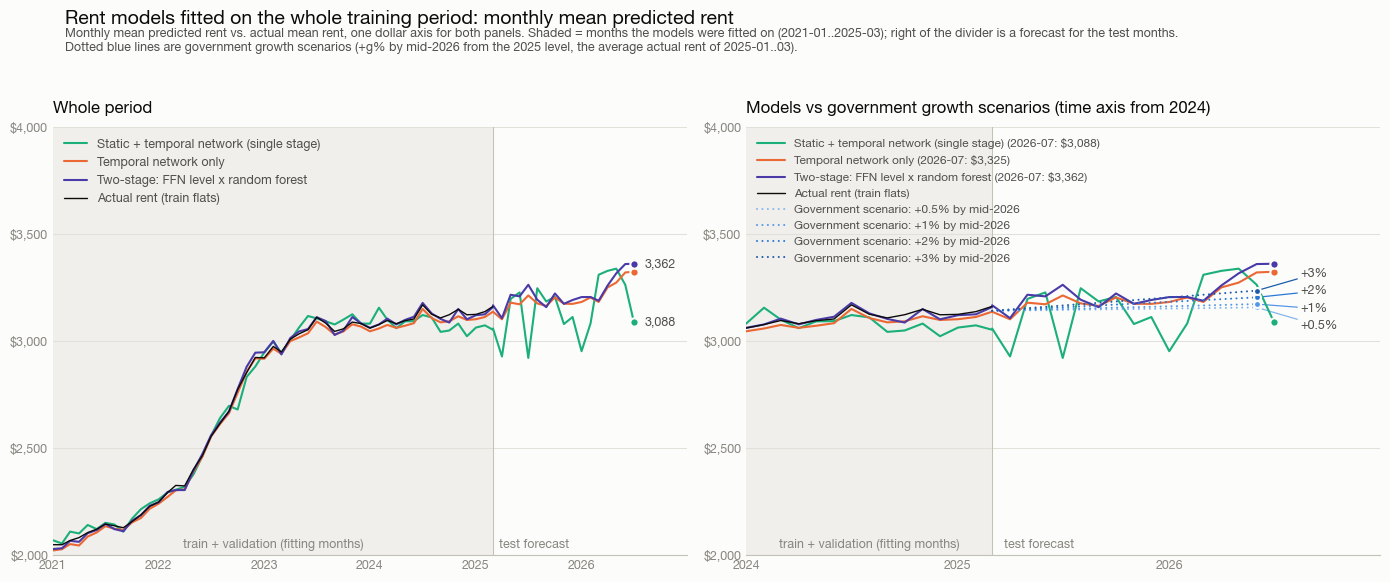

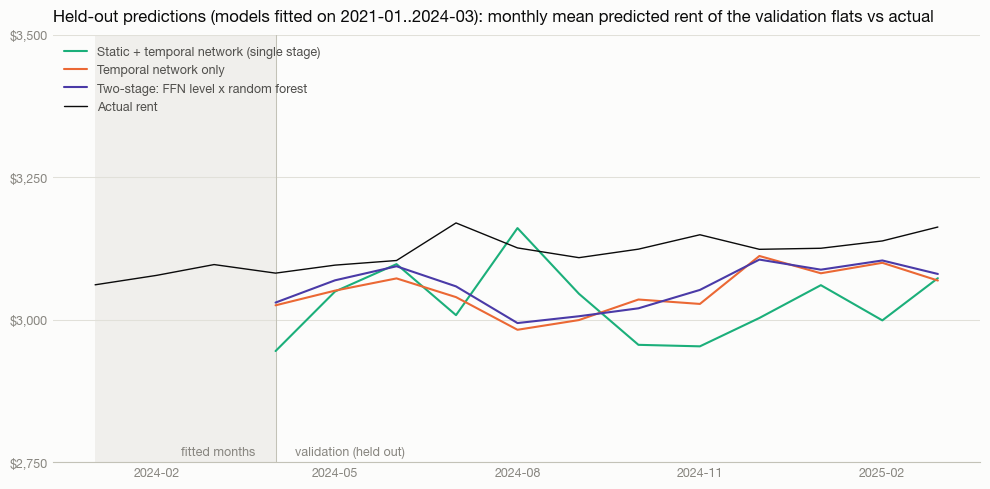

In [7]:
actual_monthly = eu.monthly_mean(train_rows['actual'], train_rows['month'])
chart_models = [{'label': label[m], 'fit': eu.monthly_mean(preds['train'][m]['prediction'], preds['train'][m]['month']),
                 'forecast': eu.monthly_mean(preds['test'][m]['prediction'], preds['test'][m]['month']), 'colour': style[m][1]} for m in models]
eu.models_chart(chart_models, actual_monthly, 'Rent models fitted on the whole training period: monthly mean predicted rent', out_path=eu.CHART_DIR / 'prediction_chart.png')
plt.show()

first_val = pd.Period(eu.month_label(FIRST_VAL)[0], freq='M')
eu.validation_chart([{'label': label[m], 'monthly': eu.monthly_mean(preds['val'][m]['prediction'], preds['val'][m]['month']), 'colour': style[m][1]} for m in models],
                    actual_monthly.loc[first_val - 3:], first_val, 'Held-out predictions (models fitted on 2021-01..2024-03): monthly mean predicted rent of the validation flats vs actual',
                    out_path=eu.CHART_DIR / 'validation_chart.png')
plt.show()

## 6. Training diagnostics of the neural networks

The epoch losses of the held-out fits (`epoch_losses_heldout.csv` in `results/tables/<model>/` of `02_modelling/two_stage_models/neural_network`): the RMSE of the training rows and of the validation rows after every epoch.
The dotted line is the held-out RMSE of the monthly mean rent.

Static + temporal network (single stage): 100 epochs; best held-out epoch 17 ($492.0), last epoch $562.6


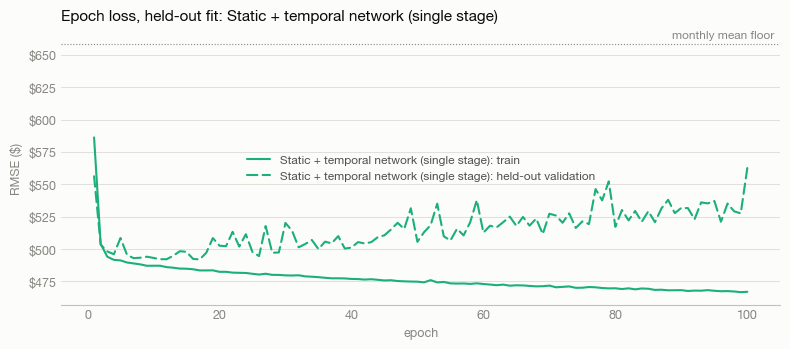

Temporal network only: 100 epochs; best held-out epoch 43 ($660.7), last epoch $664.4


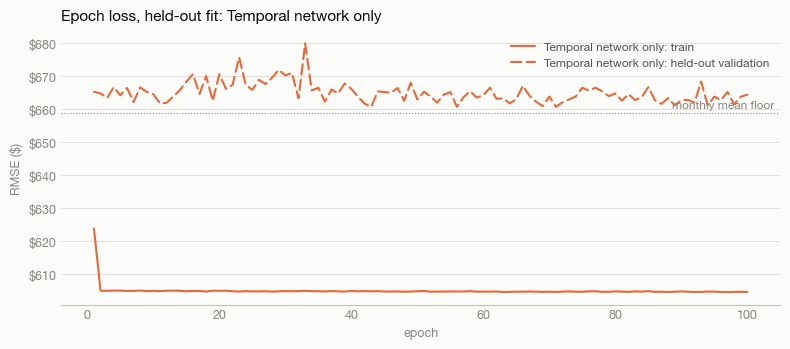

In [8]:
floor = held_out.iloc[len(models)]['RMSE']
for m in models:
    path = NN_TABLES / m / 'epoch_losses_heldout.csv'
    if not path.exists():
        continue
    h = pd.read_csv(path).set_index('epoch')
    eu.loss_chart([{'label': label[m], 'train': h['train_rmse_dollar'], 'valid': h['valid_rmse_dollar'], 'colour': style[m][1]}], f'Epoch loss, held-out fit: {label[m]}',
                  floor=(floor, 'monthly mean floor'), out_path=eu.CHART_DIR / f'epoch_loss_{m}.png')
    print(f'{label[m]}: {len(h)} epochs; best held-out epoch {h["valid_rmse_dollar"].idxmin()} (${h["valid_rmse_dollar"].min():,.1f}), last epoch ${h["valid_rmse_dollar"].iloc[-1]:,.1f}')
    plt.show()

## 7. Summary

In [9]:
summary = held_out.iloc[:len(models)].add_prefix('heldout_').join(in_sample.iloc[:len(models)][['RMSE', 'R2']].add_prefix('insample_')).join(growth[['growth at mid-2026', 'avg 2026 growth', 'distance to the 0.5-3% band']])
summary.index.name = 'model'
summary.to_csv(eu.TABLE_DIR / 'model_comparison.csv')
print(summary.round(3).to_string())

                                          heldout_MAE  heldout_RMSE  heldout_R2  heldout_BIAS  insample_RMSE  insample_R2  growth at mid-2026  avg 2026 growth  distance to the 0.5-3% band
model                                                                                                                                                                                      
Static + temporal network (single stage)      383.837       502.544       0.419       -96.569        479.731        0.591               0.060            0.043                        0.030
Temporal network only                         507.508       664.364      -0.016       -75.642        617.821        0.321               0.065            0.042                        0.035
Two-stage: FFN level x random forest          355.974       475.414       0.480       -66.554        448.645        0.642               0.065            0.042                        0.035
